# Tutorial: Making image cutouts from the data volume - start from scratch



<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) European Space Agency, 2026.

This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.

</div>

**Last modified:** 2026-11-11

**Last update:** DR1-Foundation major update.

**Notebook summary**

This example notebook presents several example use cases for making cutouts of Euclid mosaic images from a data volume on ESA Datalabs.
It is fully compatible with the DR1 realease in the PDR enviroment.
In this tutorial, you will learn how to create MOSAIC cutouts associated to:

1. ... one source observed multiple times in the EDF: it shows how to associate an observation time to each MER entry.
2. ... a list of SIMBAD sources included in the DEEP survey
2. ... a list of sources extracted from the MER (DEEP SURVEY) catalogue.


**Useful links:**

* [Euclid DR1 data product description](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [DR1 data release homepage](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [Euclid Astroquery documentation](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)


**Key TAP tables:**

The "dr1.mosaic_product" ([TAP](https://www.ivoa.net/Documents/TAP/20190927/)) table contains the metadata required to locate the observations (images) stored in the Multi-Extension FITS (MEF) files. The relevant fields that define how to access the images associated to a given source are the "fov" (the field that contains the observation footprint), and the "datalabs_path" and "file_name" fields.

**Related ADQL queries:**

In the example query below, the [INTERSECTS](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#tth_sEc4.2.17) [ADQL](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#) clause combines the target coordinates and the observation footprint (indicated by the "dr1.mosaic_product.fov" field).

```sql
SELECT reference_observation_date_time, processing_mode, purpose, release_name, datalabs_path, file_name, DISTANCE(270.4574071940534, 66.37460587298881, ra, dec) AS dist, patch_id_list
FROM dr1.mosaic_product WHERE INTERSECTS(CIRCLE(270.4574071940534, 66.37460587298881, 0.01), fov)=1
AND instrument_name = 'VIS'
AND processing_mode = 'WIDE'
ORDER BY reference_observation_date_time ASC
```



**Running the notebook:** 

* This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. 
* The notebook uses functions from the **n_utils.py Python file**. When moving the notebook you need to move this file as well. You are welcome to modify the utility file for any custom/advanced behaviour you may need.
* The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included. 
* The notebook includes a custom get_query_results method (defined in n_utils.py within this directory). This function executes an asynchronous query and outputs the query string, its results, and the total execution time.

**Version:**

* Content updated in preparation for the Euclid DR1-Foundation.
***

In [1]:
#installing necessary packages
from astroquery.esa.euclid.core import Euclid

import pandas as pd
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.table import Table, vstack, join
from astropy.io import fits
from astroquery.simbad import Simbad
import matplotlib.pyplot as plt

import os, time
import numpy as np
import getpass

from astropy import wcs
from astropy.nddata.utils import Cutout2D
from astropy.io import fits
from astropy.visualization import astropy_mpl_style, ImageNormalize, PercentileInterval, AsinhStretch, LogStretch
import matplotlib.pyplot as plt
import n_utils as utils

from astropy.visualization import simple_norm

### Creating output folder for the cutouts

First let's make a folder (if not already created) to save the output files from this notebook. All the example notebooks save their outputs to this same folder in your user workspace called: `'example_notebook_outputs/'`

In [2]:
#making a folder for the future cutouts (if not made already)
cutout_folder= '/media/user/example_notebook_outputs/cutouts/'
if not os.path.exists(cutout_folder):
    os.makedirs(cutout_folder)

**Please note:** When comparing the Q1 and DR1-foundation data releases:
* some table and column names will be different
* specific example source coordinates

It is possible to login using many different options - see the # [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) method for details. Similarly to the archive website for safety reasons this login expires after a period of time. Once this happens the queries to the archive will fail (seemingly without reason). If you are running a personal notebook that requires you to stay logged in for longer - make sure to execute this code line again every once in a while. 

In [3]:
# Alternative ways to login; uncomment your preferred one: ===========
Euclid.login()
# Euclid.login_gui()                                          # Login via graphic interface (pop-up window)
# Euclid.login(user='<user name>', password='<password>')     # 
# Euclid.logout()

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  hcanovas
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid sia service: eas.esac.esa.int:443/sas-sia/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


In [4]:
schema = 'dr1'   # DR1 schema. Change to "q1" to retrieve Q1 data, but please note that the target table names should be adapted accordingly. 

## 1. MOSAIC cutouts from multiple visits around one source included in the EDF

### 1.1 - Find a suitable source

This case builds on User Case 3 in the accompanying notebook "spectra_visualisation"

In [5]:
object_id = 2688124142666475971                                  # AGN at z=1 in EDFN; you may also try: 2661957271668287048
query = f"""select designation, object_id, right_ascension, declination, tile_index, patch_id_list, ESDC_ARRAY_LENGTH(patch_id_list,1)
FROM {schema}.mer_catalogue_deep_survey
WHERE object_id = {object_id}"""

res = utils.get_query_results(Euclid, query=query)

ADQL query: 
select designation, object_id, right_ascension, declination, tile_index, patch_id_list, ESDC_ARRAY_LENGTH(patch_id_list,1)
FROM dr1.mer_catalogue_deep_survey
WHERE object_id = 2688124142666475971

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 30.6 seconds


designation,object_id,right_ascension,declination,tile_index,patch_id_list,ARRAY_LENGTH
,NA,deg,deg,,,
object,int64,float64,float64,int64,int64[8],int32
Euclid DR1 J175514.979+663851.35,2688124142666475971,268.8124142787188,66.6475971869471,101835788,38 .. 114,11


### 1.2 - Find the associated MER DEEP_VISITS records

The target source has slightly different coordinates in the different realisations of the "deep_visits" catalogue. To identify the target source, a cone search with a 1" radius centred on the "deep survey" coordinates is launched.

In [6]:
coords_ra  = res['right_ascension'][0]
coords_dec = res['declination'][0]
rad        = 1/3600. # 1 arcseconds

query = f"""SELECT right_ascension, declination, designation, object_id, tile_index, patch_id_list AS patch_id_list_original, ESDC_ARRAY_ELEMENT(patch_id_list,1) AS patch_id_list, flux_detection_total, flux_vis_sersic,
DISTANCE({coords_ra}, {coords_dec}, right_ascension, declination)*3600. AS dist_arcsec
FROM {schema}.mer_catalogue_deep_visits
WHERE DISTANCE({coords_ra}, {coords_dec}, right_ascension, declination) < {rad}
ORDER BY patch_id_list_original ASC"""

res_1 = utils.get_query_results(Euclid, query=query)

ADQL query: 
SELECT right_ascension, declination, designation, object_id, tile_index, patch_id_list AS patch_id_list_original, ESDC_ARRAY_ELEMENT(patch_id_list,1) AS patch_id_list, flux_detection_total, flux_vis_sersic,
DISTANCE(268.8124142787188, 66.6475971869471, right_ascension, declination)*3600. AS dist_arcsec
FROM dr1.mer_catalogue_deep_visits
WHERE DISTANCE(268.8124142787188, 66.6475971869471, right_ascension, declination) < 0.0002777777777777778
ORDER BY patch_id_list_original ASC

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 29.7 seconds


right_ascension,declination,designation,object_id,tile_index,patch_id_list_original,patch_id_list,flux_detection_total,flux_vis_sersic,dist_arcsec
deg,deg,,NA,,,,uJy,uJy,
float64,float64,object,int64,int64,int64,object,float64,float64,float64
268.8124190420673,66.6475974278564,Euclid DR1 J175514.980+663851.35,2688124190666475974,102159486,39,39,14.389762878417969,14.576122283935547,0.0068523428155623746
268.8124183452948,66.64759743443175,Euclid DR1 J175514.980+663851.35,2688124183666475974,102159486,44,44,14.610295295715332,14.796005249023438,0.005870948485387208
268.8124154337758,66.64759722358156,Euclid DR1 J175514.979+663851.35,2688124154666475972,102159486,49,49,15.388643264770508,15.378669738769531,0.0016535195514228952
268.8124122139963,66.64759652980936,Euclid DR1 J175514.978+663851.35,2688124122666475965,102159486,57,57,15.179048538208008,14.852352142333984,0.00377854379842956
268.81241312420985,66.64759795398962,Euclid DR1 J175514.979+663851.35,2688124131666475979,102159486,64,64,15.190481185913086,15.294349670410156,0.0032154667833326715
268.81240800552666,66.64759574448236,Euclid DR1 J175514.977+663851.34,2688124080666475957,102159486,99,99,16.514841079711914,16.523481369018555,0.010348914726671505
268.8124151117189,66.64759757966317,Euclid DR1 J175514.979+663851.35,2688124151666475975,102159486,114,114,15.506856918334961,15.619490623474121,0.0018470867040115441
268.8124096358153,66.64759669986377,Euclid DR1 J175514.978+663851.35,2688124096666475966,102159486,130,130,16.09809112548828,16.165904998779297,0.006853481801334715


### 1.3 - Find the associated MOSAIC VIS images

Notes:
* The query that must be launched uses the [INTERSECTS](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#tth_sEc4.2.17) ADQL clause combining the target coordinates and the observation footprint (indicated by the "dr1.mosaic_product.fov" field).
* To obtain NISP cutouts, change the filter on the "instrument_name" field in the query below from "VIS" to "NISP"
* The [Background-Subtracted Mosaic images](http://st-dm.pages.euclid-sgs.uk/data-product-doc/dmdr1/merdpd/dpcards/mer_bksmosaic.html) combine all the imaging data that overlap the MER tiles. Their FITS files include the following useful metadata:
    * PatchIdList: The sky patch ids associated to the product.
    * ObservationIdList: List of unique IDs identifying the Euclid observations that were used to generate the product.
    * ProcessingMode: The MER pipeline processing mode (e.g. WIDE, DEEP) used to generate the product.
    * ReferenceObservationDateTime: Reference observation date time for Gaia proper motion correction (only applicable to Euclid observations).
    * FirstObservationDateTime: Observation date time of the first Euclid observation used to generate the product.
    * LastObservationDateTime: Observation date time of the last Euclid observation used to generate the product.

In [7]:
rad      = 1/60. # [Degrees]: radius applied to identify observations that cover the sky region where the target source is located.
scols    = """first_observation_date_time, reference_observation_date_time, last_observation_date_time, processing_mode, purpose, release_name, datalabs_path, file_name, filter_name, patch_id_list, observation_id_list"""

query = f"""SELECT {scols}
FROM {schema}.mosaic_product WHERE INTERSECTS(CIRCLE({coords_ra}, {coords_dec}, {rad}), fov)=1
AND instrument_name = 'VIS'
AND processing_mode = 'WIDE'
ORDER BY reference_observation_date_time ASC"""

res_2 = utils.get_query_results(Euclid, query=query, display_rows=3)

ADQL query: 
SELECT first_observation_date_time, reference_observation_date_time, last_observation_date_time, processing_mode, purpose, release_name, datalabs_path, file_name, filter_name, patch_id_list, observation_id_list
FROM dr1.mosaic_product WHERE INTERSECTS(CIRCLE(268.8124142787188, 66.6475971869471, 0.016666666666666666), fov)=1
AND instrument_name = 'VIS'
AND processing_mode = 'WIDE'
ORDER BY reference_observation_date_time ASC

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 22.3 seconds
* Job output contains 10 rows; displaying first 3 rows: 


first_observation_date_time,reference_observation_date_time,last_observation_date_time,processing_mode,purpose,release_name,datalabs_path,file_name,filter_name,patch_id_list,observation_id_list
object,object,object,object,object,object,object,object,object,object,object
2024-06-14T21:57:25.201,2024-06-15T02:42:49.232,2024-06-15T07:28:05.263,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-D20C7_20250717T230105.344554Z_00.00.fits,VIS,39,2090 2091 2096 2097
2024-06-22T12:07:46.394,2024-06-22T18:06:55.933,2024-06-23T00:06:13.472,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-43615F_20250727T025622.998022Z_00.00.fits,VIS,44,2204 2205 2212 2213
2024-07-18T08:53:23.509,2024-07-18T10:24:58.519,2024-07-18T22:05:35.596,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-E4E157_20250723T081950.087483Z_00.00.fits,VIS,49,2693 2694 2703


### 1.4 Merge the MER data with the MOSAIC images metadata

The information from the MER catalogue and the FITS (Mosaic) images is merged in the cell below via the common ```patch_id_list``` field. This way, it is possible to associate an observing time to each MER entry.

In [8]:
final = join(res_1, res_2, keys='patch_id_list')
final

right_ascension,declination,designation,object_id,tile_index,patch_id_list_original,patch_id_list,flux_detection_total,flux_vis_sersic,dist_arcsec,first_observation_date_time,reference_observation_date_time,last_observation_date_time,processing_mode,purpose,release_name,datalabs_path,file_name,filter_name,observation_id_list
deg,deg,,NA,,,,uJy,uJy,,,,,,,,,,,
float64,float64,object,int64,int64,int64,object,float64,float64,float64,object,object,object,object,object,object,object,object,object,object
268.8124151117189,66.64759757966317,Euclid DR1 J175514.979+663851.35,2688124151666475975,102159486,114,114,15.506856918334961,15.619490623474121,0.0018470867040115441,2024-12-30T03:49:23.778,2024-12-30T05:38:44.79,2024-12-30T13:20:04.842,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-CB6859_20250723T180541.288055Z_00.00.fits,VIS,5564 5565 5570 5571
268.8124096358153,66.64759669986377,Euclid DR1 J175514.978+663851.35,2688124096666475966,102159486,130,130,16.09809112548828,16.165904998779297,0.006853481801334715,2025-01-31T17:57:39.996,2025-01-31T23:56:51.036,2025-02-01T05:56:10.076,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-1CC142_20250721T073616.919097Z_00.00.fits,VIS,6152 6153 6160 6161
268.8124111494279,66.64759925196044,Euclid DR1 J175514.978+663851.36,2688124111666475992,102159486,151,151,14.490004539489746,14.899300575256348,0.008672103914871847,2025-03-21T17:25:27.837,2025-03-21T22:10:53.87,2025-03-22T02:56:11.902,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-E30A6B_20250716T122001.217862Z_00.00.fits,VIS,6878 6879 6884 6885
268.81242530523895,66.64759489298966,Euclid DR1 J175514.982+663851.34,2688124253666475948,102159486,171,171,20.98210906982422,5.95076322555542,0.017770187543263986,2025-05-11T05:07:40.021,2025-05-11T11:06:44.562,2025-05-11T17:05:57.102,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-BB642D_20250718T024945.484752Z_00.00.fits,VIS,7780 7781 7788 7789
268.8124190420673,66.6475974278564,Euclid DR1 J175514.980+663851.35,2688124190666475974,102159486,39,39,14.389762878417969,14.576122283935547,0.0068523428155623746,2024-06-14T21:57:25.201,2024-06-15T02:42:49.232,2024-06-15T07:28:05.263,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-D20C7_20250717T230105.344554Z_00.00.fits,VIS,2090 2091 2096 2097
268.8124183452948,66.64759743443175,Euclid DR1 J175514.980+663851.35,2688124183666475974,102159486,44,44,14.610295295715332,14.796005249023438,0.005870948485387208,2024-06-22T12:07:46.394,2024-06-22T18:06:55.933,2024-06-23T00:06:13.472,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-43615F_20250727T025622.998022Z_00.00.fits,VIS,2204 2205 2212 2213
268.8124154337758,66.64759722358156,Euclid DR1 J175514.979+663851.35,2688124154666475972,102159486,49,49,15.388643264770508,15.378669738769531,0.0016535195514228952,2024-07-18T08:53:23.509,2024-07-18T10:24:58.519,2024-07-18T22:05:35.596,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-E4E157_20250723T081950.087483Z_00.00.fits,VIS,2693 2694 2703
268.8124122139963,66.64759652980936,Euclid DR1 J175514.978+663851.35,2688124122666475965,102159486,57,57,15.179048538208008,14.852352142333984,0.00377854379842956,2024-08-04T15:43:20.248,2024-08-04T23:06:49.297,2024-08-05T01:14:04.311,WIDE,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/102159486/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE102159486-B77A17_20250720T130434.667995Z_00.00.fits,VIS,2990 2991 2996 2997


### 1.5 Generate the Cutouts

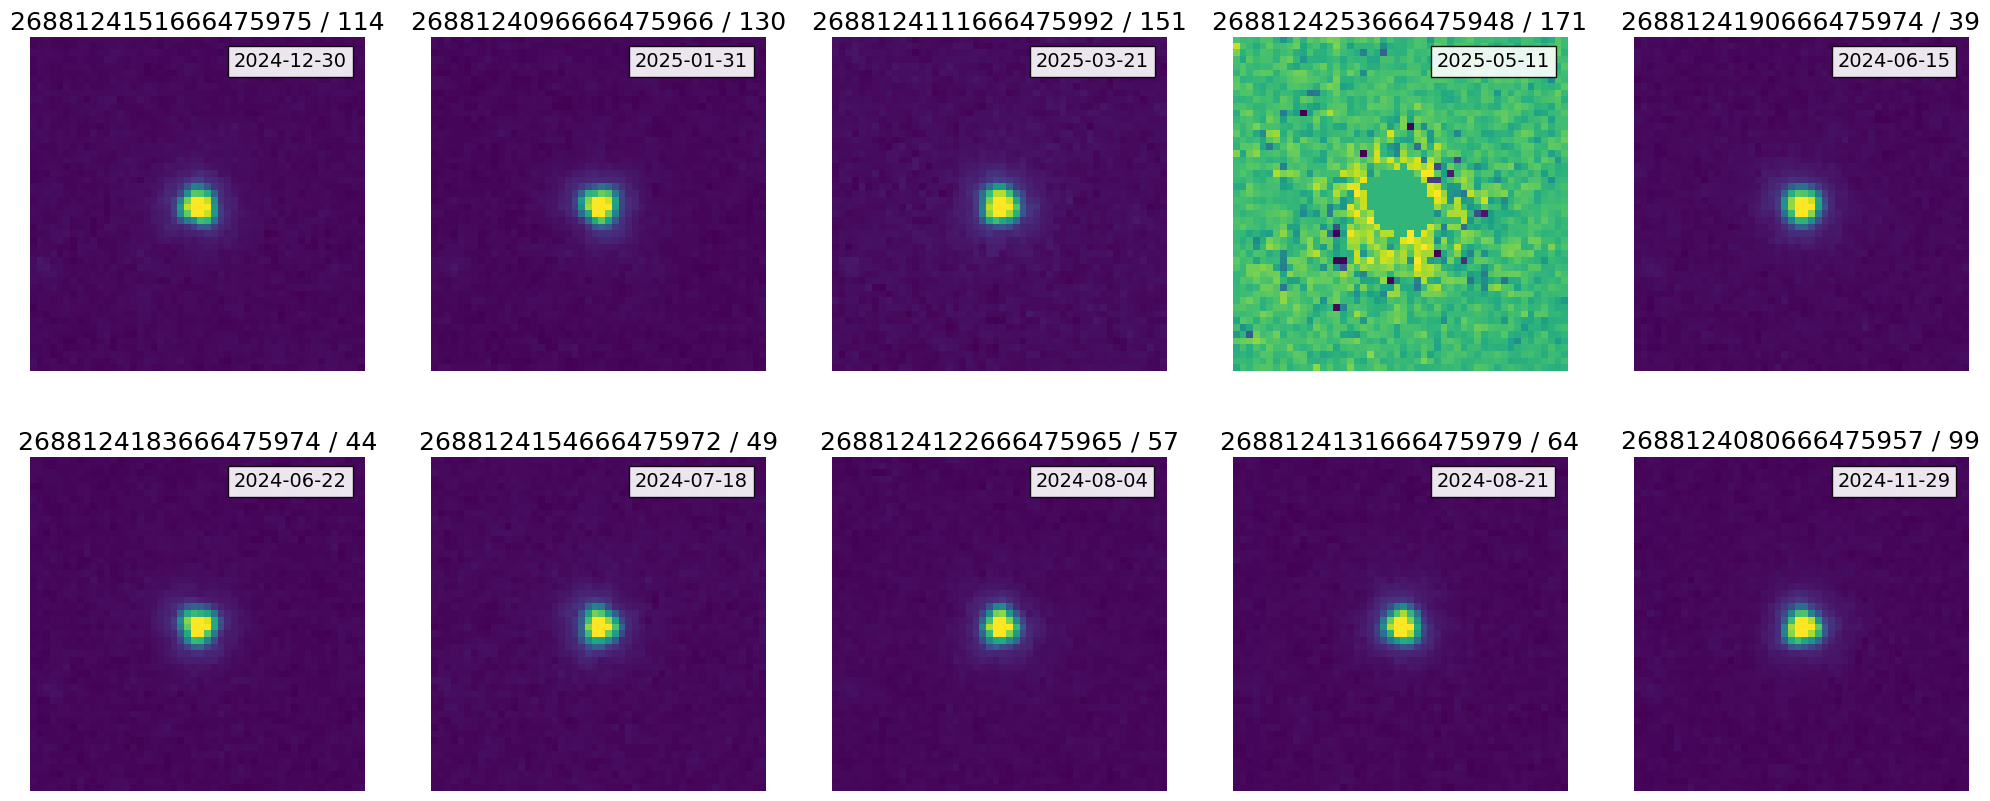

In [9]:
# Cutouts generation ============
subset      = final
cutout_r    = 5 * u.arcsecond # Cutout size (height x weight)
cutout_list = []
coords      = SkyCoord(coords_ra, coords_dec, unit="deg")

for ii in range(len(subset)):
    file_path     = f"{subset['datalabs_path'][ii]}/{subset['file_name'][ii]}"
    hdul          = fits.open(file_path)
    cutout        = Cutout2D(data=hdul[0].data, position = coords, size= cutout_r, wcs=wcs.WCS(hdul[0].header))
    cutout_list.append(cutout)
    hdul.close()


# Plot images ===================
list_title  = [f"{inp['object_id']} / {inp['patch_id_list']}" for inp in subset]
list_date   = [f"{inp['reference_observation_date_time'][0:10]}"    for inp in subset]

plt.figure(figsize=[25,10])

for ii in range(10):
    ax = plt.subplot(2,5,1 + ii)
    ax.imshow(cutout_list[ii].data, cmap='viridis', origin='lower', norm = ImageNormalize(cutout_list[ii].data, interval=PercentileInterval(99.5), stretch=AsinhStretch()))
    ax.set_title(list_title[ii], fontsize=18)
    
    x, y, w, h = 30, 40, 0, 0  
    ax.text(x, y + h + 5, list_date[ii],fontsize=14,bbox=dict(facecolor='white', alpha=0.9))
    ax.axis('off')

plt.show()
    
# To export the image as png:
# png_name = 'cutout_example.png'
# plt.savefig(png_name, dpi=300, bbox_inches='tight', pad_inches=0)    

## Intermezzo: MOSAICS + PROCESSING MODE = DEEP


In [10]:
rad      = 0.01/60. # [Degrees]: radius applied to identify observations that cover the sky region where the target source is located.
scols    = """reference_observation_date_time, processing_mode, ra, dec, purpose, release_name, datalabs_path, file_name, filter_name, patch_id_list, observation_id_list"""

query = f"""SELECT {scols}, DISTANCE({coords_ra}, {coords_dec}, ra, dec)*60 AS sep_arcmin
FROM {schema}.mosaic_product WHERE INTERSECTS(CIRCLE({coords_ra}, {coords_dec}, {rad}), fov)=1
AND instrument_name = 'VIS'
AND processing_mode = 'DEEP'
ORDER BY reference_observation_date_time ASC"""

res = utils.get_query_results(Euclid,query, display_rows=3)

ADQL query: 
SELECT reference_observation_date_time, processing_mode, ra, dec, purpose, release_name, datalabs_path, file_name, filter_name, patch_id_list, observation_id_list, DISTANCE(268.8124142787188, 66.6475971869471, ra, dec)*60 AS sep_arcmin
FROM dr1.mosaic_product WHERE INTERSECTS(CIRCLE(268.8124142787188, 66.6475971869471, 0.00016666666666666666), fov)=1
AND instrument_name = 'VIS'
AND processing_mode = 'DEEP'
ORDER BY reference_observation_date_time ASC

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 22.5 seconds
* Job output contains 1 rows; displaying first 3 rows: 


reference_observation_date_time,processing_mode,ra,dec,purpose,release_name,datalabs_path,file_name,filter_name,patch_id_list,observation_id_list,sep_arcmin
object,object,float64,float64,object,object,object,object,object,object,object,float64
2024-08-21T16:49:47.45,DEEP,268.9661452729,66.75,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/101835788/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE101835788-60107B_20250823T055703.839205Z_00.00.fits,VIS,"38,39,44,49,57,64,99,114,130,151,171",2046 2047 2090 2091 2204 2205 2693 2996 2997 3316 3317 5009 5010 5571 6152 6153 6879 6884 7780 7789,7.145856934217854


- reading: /data/euclid_idr1/DR1/R1/MER/101835788/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101835788-60107B_20250823T055703.839205Z_00.00.fits



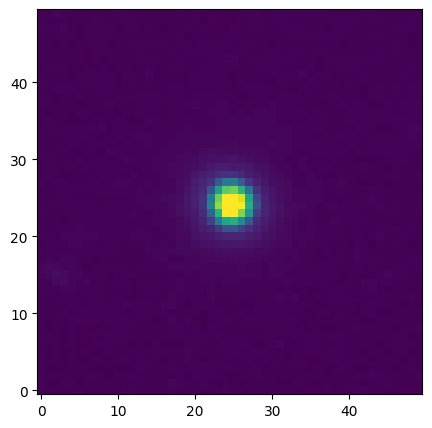

In [11]:
# Cutouts generation ============
subset      = res
cutout_r    = 5 * u.arcsecond # Cutout size (height x weight)

file_path  = f"{subset['datalabs_path'][0]}/{subset['file_name'][0]}"
print(f'- reading: {file_path}')
print()

hdul          = fits.open(file_path)
cutout        = Cutout2D(data=hdul[0].data, position = coords, size= cutout_r, wcs=wcs.WCS(hdul[0].header ))
hdul.close()


# Plot images ===================
plt.figure(figsize=[7,5])

ax = plt.subplot(1,1,1)
ax.imshow(cutout.data, cmap='viridis', origin='lower', norm = ImageNormalize(cutout.data, interval=PercentileInterval(99.5), stretch=AsinhStretch()))

plt.show()

## 2. Create MOSAIC cutouts associated to a list of (Simbad names) DEEP sources


When dealing with lists of input coordinates or source ids, the recommended approach is to first upload the target list to the user space - Please see the accompanning "Astroquery" notebook, and the "Use case 3" in the accompanning "Spectra_visualisation" notebook.

### 2.1: Gather the SIMBAD coordinates

The coordinates of three Galaxies featured in this [Euclid Nearby Galaxies Collage](https://www.cosmos.esa.int/web/euclid/euclid-nearby-galaxies-collage) are obtained using the [Astropy.Skycoords](https://docs.astropy.org/en/stable/api/astropy.coordinates.SkyCoord.html) package.

Note: these coordinates come from the SIMBAD database and are therefore in epoch J2000. It is likely that the coordinates of these objects in the Euclid observations have changed (slightly) due to their proper motions, but this effect is negligible for this use case.

In [12]:
inp_names  = ['PGC 129576', 'PGC 129507', 'PGC 2679728']
coords     = [SkyCoord.from_name(inp_name) for inp_name in inp_names]
coords_ra  = [coord.ra.deg for coord in coords]
coords_dec = [coord.dec.deg for coord in coords]

table_name = 'cutouts_tutorial_input'        # Table name at the user space
my_table   = Table([inp_names, coords_ra, coords_dec], names=['inp_id', 'ra', 'dec'])
my_table

inp_id,ra,dec
str11,float64,float64
PGC 129576,64.8827667,-48.2849083
PGC 129507,60.95899112066999,-50.08558912093001
PGC 2679728,274.220275,65.6863639


### 2.2: Upload table to the user space

The code below first checks if the user table is already present in the Archive user space.

**Notes:** 
* Please remember to not include special [ADQL characters](https://www.ivoa.net/documents/ADQL/20230418/PR-ADQL-2.1-20230418.pdf) in the table name (e.g., a dot "." or a minus sign "-" can generate problems when trying to access to the user table in the database). We also recommmend to not use capital letters in the table name.
* If the user table already exists in the user space, the code will not overwrite it, but stop the upload.

In [13]:
user       = getpass.getuser()                                                                                    # User name
utables    = Euclid.load_tables(only_names=True)                                                                  # Get names of Archive tables
my_utables = [utable.get_qualified_name() for utable in utables if f'user_{user}' in utable.get_qualified_name()] # Extract user table names
print(f'User tables found in the Archive: ')
for my_utable in my_utables:
    print(f'* {my_utable}')
    

fq_name    = f'user_{user}.{table_name}'
if fq_name in my_utables:
    print(f'* Warning: {table_name} exist on the user space - stopping table upload')
else:
    Euclid.upload_table(upload_resource=my_table, table_name = table_name)

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
User tables found in the Archive: 
* user_hcanovas.cutouts_tutorial_input
* user_hcanovas.des_target_sources
* user_hcanovas.input_spec_list
* user_hcanovas.my_q1_source_list
* user_hcanovas.spec_tutorial_input
* Warning: cutouts_tutorial_input exist on the user space - stopping table upload


### 2.3: Cross-match with the MER (DEEP SURVEY) catalogue

The query below requires ~ 20 seconds to finish. Alternatively, the cross-match operation can be done directly on the "dr1.mosaic_product" table.

In [14]:
query = f"""SELECT my_table.*, mer.right_ascension, mer.declination, mer.object_id, mer.tile_index, mer.patch_id_list AS patch_id_list_original, ESDC_ARRAY_ELEMENT(mer.patch_id_list,1) AS patch_id_list,
mer.flux_detection_total, mer.flux_vis_sersic, DISTANCE(my_table.ra, my_table.dec, mer.right_ascension, mer.declination) AS ang_sep
FROM user_{user}.{table_name} AS my_table
JOIN {schema}.mer_catalogue_deep_survey AS mer
ON DISTANCE(my_table.ra, my_table.dec, mer.right_ascension, mer.declination) < 1./3600."""

res = utils.get_query_results(Euclid, query)

ADQL query: 
SELECT my_table.*, mer.right_ascension, mer.declination, mer.object_id, mer.tile_index, mer.patch_id_list AS patch_id_list_original, ESDC_ARRAY_ELEMENT(mer.patch_id_list,1) AS patch_id_list,
mer.flux_detection_total, mer.flux_vis_sersic, DISTANCE(my_table.ra, my_table.dec, mer.right_ascension, mer.declination) AS ang_sep
FROM user_hcanovas.cutouts_tutorial_input AS my_table
JOIN dr1.mer_catalogue_deep_survey AS mer
ON DISTANCE(my_table.ra, my_table.dec, mer.right_ascension, mer.declination) < 1./3600.

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 29.4 seconds


cutouts_tutorial_input_oid,inp_id,ra,dec,right_ascension,declination,object_id,tile_index,patch_id_list_original,patch_id_list,flux_detection_total,flux_vis_sersic,ang_sep
,,,,deg,deg,NA,,,,uJy,uJy,
int32,object,float64,float64,float64,float64,int64,int64,int64[8],object,float64,float64,float64
3,PGC 2679728,274.220275,65.6863639,274.2205435971991,65.68640299764408,2742205435656864029,101833458,38 .. 114,38,2187.6357421875,2007.109375,0.00011729759127975775
2,PGC 129507,60.95899112066999,-50.08558912093001,60.95890382232392,-50.08562875297623,-609589038500856287,101277682,62 .. 115,62,3656.37451171875,2911.339111328125,6.861706930328145e-05
1,PGC 129576,64.8827667,-48.2849083,64.88274119244458,-48.28491398217191,-648827411482849139,101284314,62 .. 115,62,1975.3909912109375,2001.632080078125,1.7899270809881355e-05


### 2.4 - Find the associated MOSAIC VIS images

**Notes:**
* In this case, the ADQL syntax differs slightly from previous examples. It uses a ```JOIN ... ON ... INTERSECTS()``` construct, which is analogous to the syntax employed for cross-matching catalogues using ```JOIN ... ON ... DISTANCE()```.

* **Important**: 
    * There are two pointings that include observations of the object LEDA 129507. The tile_index associated with this source in the MER catalogue is 101277682. However, the dr1.mosaic_product table reveals that two different files contain observations of this source, with tile_index values 101277681 and 101277682.

    * The dist_cent field computed in the ADQL query represents the angular distance between the object and the center of each MOSAIC observation. As expected, the observation in which the source lies closest to the image center corresponds to the same tile_index (101277682) listed in the MER catalogue.
    
    * Multiple observations can happen and users are advised to check for this.

In [15]:
rad        = 1/60. # [Degrees]: radius applied to identify observations that cover the sky region where the target source is located.
scols      = ['first_observation_date_time', 'reference_observation_date_time', 'last_observation_date_time', 'processing_mode', 'purpose', 'release_name', 
              'datalabs_path', 'file_name', 'filter_name', 'patch_id_list', 'tile_index']
scols      = [f'mosaic.{inp}' for inp in scols]
scols      = ",".join(scols)

instrument = 'VIS'

query = f"""SELECT my_table.*, {scols}, DISTANCE(my_table.ra, my_table.dec, mosaic.ra, mosaic.dec) AS dist_cent
FROM {schema}.mosaic_product AS mosaic
JOIN user_{user}.{table_name} AS my_table
  ON INTERSECTS(CIRCLE(my_table.ra, my_table.dec, {rad}), fov)=1
WHERE instrument_name = '{instrument}'
AND processing_mode = 'DEEP'
ORDER BY my_table.inp_id
"""
res = utils.get_query_results(Euclid, query)

ADQL query: 
SELECT my_table.*, mosaic.first_observation_date_time,mosaic.reference_observation_date_time,mosaic.last_observation_date_time,mosaic.processing_mode,mosaic.purpose,mosaic.release_name,mosaic.datalabs_path,mosaic.file_name,mosaic.filter_name,mosaic.patch_id_list,mosaic.tile_index, DISTANCE(my_table.ra, my_table.dec, mosaic.ra, mosaic.dec) AS dist_cent
FROM dr1.mosaic_product AS mosaic
JOIN user_hcanovas.cutouts_tutorial_input AS my_table
  ON INTERSECTS(CIRCLE(my_table.ra, my_table.dec, 0.016666666666666666), fov)=1
WHERE instrument_name = 'VIS'
AND processing_mode = 'DEEP'
ORDER BY my_table.inp_id


INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 32.1 seconds


cutouts_tutorial_input_oid,inp_id,ra,dec,first_observation_date_time,reference_observation_date_time,last_observation_date_time,processing_mode,purpose,release_name,datalabs_path,file_name,filter_name,patch_id_list,tile_index,dist_cent
int32,object,float64,float64,object,object,object,object,object,object,object,object,object,object,int64,float64
2,PGC 129507,60.95899112066999,-50.08558912093001,2024-08-14T15:21:27.831,2024-09-27T09:32:34.263,2025-01-22T16:32:25.546,DEEP,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/101277681/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE101277681-6275AF_20251014T045143.237068Z_00.00.fits,VIS,"62,67,71,74,78,107,111,115,123,126",101277681,0.16089100267377626
2,PGC 129507,60.95899112066999,-50.08558912093001,2024-08-14T16:14:45.837,2024-09-27T15:22:58.805,2025-01-22T16:32:25.546,DEEP,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/101277682/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE101277682-193D3C_20251012T011937.040048Z_00.00.fits,VIS,"62,67,71,74,78,107,111,115,123,126",101277682,0.1411585512313934
1,PGC 129576,64.8827667,-48.2849083,2024-08-15T15:59:07.993,2024-09-28T05:06:03.895,2025-01-23T17:09:53.71,DEEP,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/101284314/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE101284314-2AA6D5_20250930T191200.818696Z_00.00.fits,VIS,"62,67,71,74,78,107,111,115,123,126",101284314,0.09143925111005458
3,PGC 2679728,274.220275,65.6863639,2024-06-12T23:23:56.896,2024-11-29T06:52:13.835,2025-05-11T12:45:28.072,DEEP,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/101833458/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE101833458-52BB56_20250828T142405.645231Z_00.00.fits,VIS,"38,39,44,49,57,64,99,114,130,151,171",101833458,0.07142373471321145


0 - reading: /data/euclid_idr1/DR1/R1/MER/101277682/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101277682-193D3C_20251012T011937.040048Z_00.00.fits
1 - reading: /data/euclid_idr1/DR1/R1/MER/101284314/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101284314-2AA6D5_20250930T191200.818696Z_00.00.fits
2 - reading: /data/euclid_idr1/DR1/R1/MER/101833458/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101833458-52BB56_20250828T142405.645231Z_00.00.fits


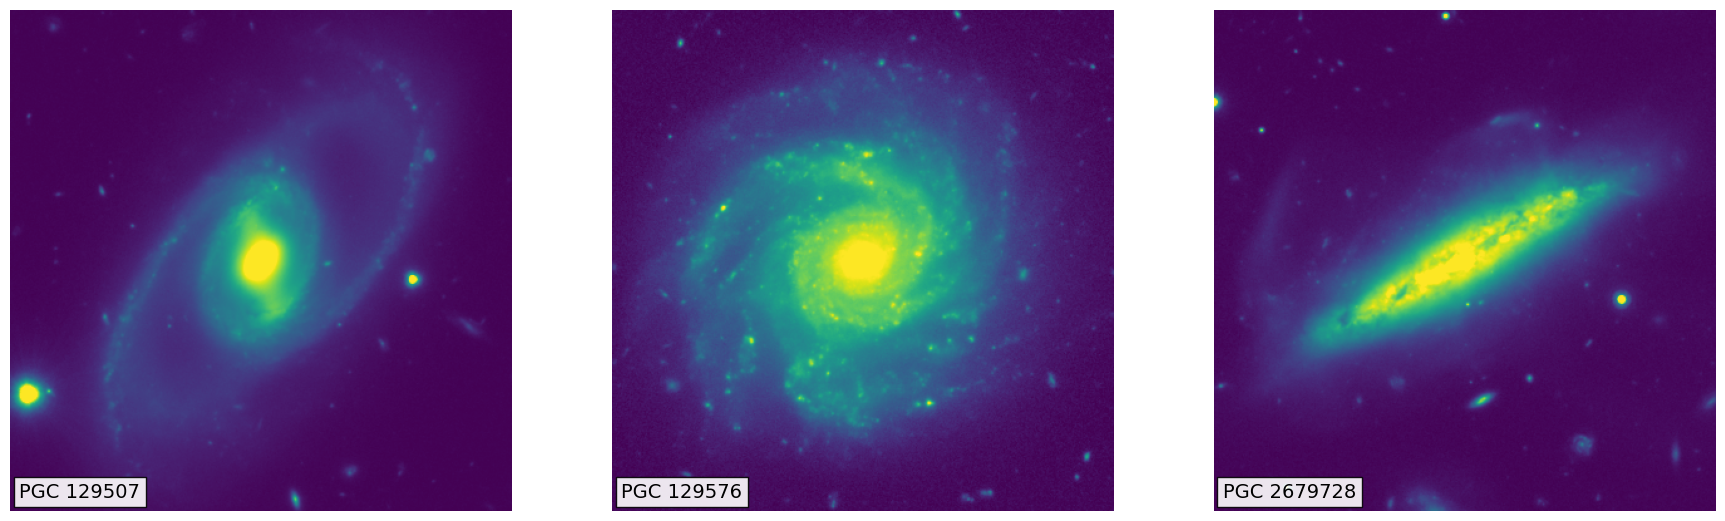

In [16]:
# Cutouts generation ============
subset      = res[1:] # (exclusing the first row to avoid duplication)
cutout_r    = 40 * u.arcsecond # Cutout size (height x weight)
cutout_list = []

coords      = [SkyCoord(inp['ra']*u.deg, inp['dec']* u.deg)   for inp in subset]
for ii in range(len(subset)):
    file_path  = f"{subset['datalabs_path'][ii]}/{subset['file_name'][ii]}"
    print(f'{ii} - reading: {file_path}')
    
    hdul          = fits.open(file_path)
    cutout        = Cutout2D(data=hdul[0].data, position = coords[ii], size= cutout_r, wcs=wcs.WCS(hdul[0].header))
    cutout_list.append(cutout)
    hdul.close()
    

list_title  = [f"{inp}"                                       for inp in range(len(subset))]
list_date   = [f"{inp['reference_observation_date_time']}"    for inp in subset]

# Plot images ===================
plt.figure(figsize=[22,7])

for ii in range(len(subset)):
    ax = plt.subplot(1,len(subset),1 + ii)
    ax.imshow(cutout_list[ii].data, cmap='viridis', origin='lower', norm = ImageNormalize(cutout_list[ii].data, interval=PercentileInterval(99.), stretch=AsinhStretch()))
    
    x, y, w, h = 7, 5, 0, 0
    ax.text(x, y + h + 5, subset['inp_id'][ii],fontsize=14,bbox=dict(facecolor='white', alpha=0.9))
    ax.axis('off')

plt.show()

## 3. Create MOSAIC cutouts associated to a list of sources included in the DEEP SURVEY catalogue

In this use case, it is not always necessary to upload the table list to the user space. Instead, the query used to generate the input list can be inserted inside am ADQL [WITH](https://www.ivoa.net/Documents/ADQL/20231215/REC-ADQL-2.1.html#tth_sEc4.5.1) operator as detailed below. If the input source list contains many (say >10,000) sources, then we suggest to first upload that list to the user space as in the previous example.

### 3.1: Gather the MER source list



In [17]:
tile_index = 101832848

query_1 = f"""SELECT right_ascension, declination, object_id, tile_index, patch_id_list, flux_detection_total, flux_vis_sersic, flux_segmentation, ellipticity
FROM {schema}.mer_catalogue_deep_survey AS mer
WHERE tile_index = {101832848}
AND NULLIF(flux_vis_sersic, 'NaN') > 1000.
AND ellipticity > 0.15"""

res = utils.get_query_results(Euclid, query_1, display_rows=3)

ADQL query: 
SELECT right_ascension, declination, object_id, tile_index, patch_id_list, flux_detection_total, flux_vis_sersic, flux_segmentation, ellipticity
FROM dr1.mer_catalogue_deep_survey AS mer
WHERE tile_index = 101832848
AND NULLIF(flux_vis_sersic, 'NaN') > 1000.
AND ellipticity > 0.15

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 27.7 seconds
* Job output contains 27 rows; displaying first 3 rows: 


right_ascension,declination,object_id,tile_index,patch_id_list,flux_detection_total,flux_vis_sersic,flux_segmentation,ellipticity
deg,deg,NA,,,uJy,uJy,uJy,NA
float64,float64,int64,int64,int64[8],float64,float64,float64,float64
267.75661175553546,65.53781092682195,2677566117655378109,101832848,38 .. 114,574.0881958007812,1615.0821533203125,552.7171630859375,0.6944206953048706
267.79151076741147,65.50383783384632,2677915107655038378,101832848,38 .. 114,1248.860595703125,1061.0469970703125,1213.53857421875,0.5003247857093811
267.7813145427671,65.53100719954608,2677813145655310071,101832848,38 .. 114,23316.30859375,23300.837890625,22876.876953125,0.20745089650154114


In [18]:
rad      = 20/3600. # [Degrees]: radius applied to identify observations that cover the sky region where the target source is located. Watch out! Errors can appear if the source is too close to the image edges (it happens when rad increases)

query = f"""WITH my_table AS ({query_1})

SELECT my_table.*, mosaic.first_observation_date_time, mosaic.reference_observation_date_time, mosaic.last_observation_date_time, mosaic.processing_mode, 
mosaic.purpose, mosaic.release_name, mosaic.datalabs_path, mosaic.file_name, mosaic.filter_name, mosaic.tile_index, DISTANCE(my_table.right_ascension, my_table.declination, mosaic.ra, mosaic.dec)*60 AS dist
FROM my_table
JOIN {schema}.mosaic_product AS mosaic
  ON INTERSECTS(CIRCLE(my_table.right_ascension, my_table.declination, {rad}), mosaic.fov)=1
WHERE mosaic.instrument_name = 'VIS'
AND mosaic.processing_mode = 'DEEP'
AND mosaic.tile_index = {tile_index}
ORDER BY my_table.object_id

"""
res = utils.get_query_results(Euclid, query, display_rows = 3)

ADQL query: 
WITH my_table AS (SELECT right_ascension, declination, object_id, tile_index, patch_id_list, flux_detection_total, flux_vis_sersic, flux_segmentation, ellipticity
FROM dr1.mer_catalogue_deep_survey AS mer
WHERE tile_index = 101832848
AND NULLIF(flux_vis_sersic, 'NaN') > 1000.
AND ellipticity > 0.15)

SELECT my_table.*, mosaic.first_observation_date_time, mosaic.reference_observation_date_time, mosaic.last_observation_date_time, mosaic.processing_mode, 
mosaic.purpose, mosaic.release_name, mosaic.datalabs_path, mosaic.file_name, mosaic.filter_name, mosaic.tile_index, DISTANCE(my_table.right_ascension, my_table.declination, mosaic.ra, mosaic.dec)*60 AS dist
FROM my_table
JOIN dr1.mosaic_product AS mosaic
  ON INTERSECTS(CIRCLE(my_table.right_ascension, my_table.declination, 0.005555555555555556), mosaic.fov)=1
WHERE mosaic.instrument_name = 'VIS'
AND mosaic.processing_mode = 'DEEP'
AND mosaic.tile_index = 101832848
ORDER BY my_table.object_id



INFO: Query finished. [astroq

right_ascension,declination,tile_index,flux_detection_total,flux_segmentation,flux_vis_sersic,patch_id_list,object_id,ellipticity,first_observation_date_time,reference_observation_date_time,last_observation_date_time,processing_mode,purpose,release_name,datalabs_path,file_name,filter_name,tile_index2,dist
deg,deg,,uJy,uJy,uJy,,NA,NA,,,,,,,,,,,
float64,float64,int64,float64,float64,float64,int64[8],int64,float64,object,object,object,object,object,object,object,object,object,int64,float64
267.2724247680601,65.42411581644174,101832848,7223.072265625,7641.20458984375,7208.70361328125,38 .. 114,2672724247654241158,0.15769840776920319,2024-06-13T08:57:41.959,2024-12-29T18:15:56.715,2025-05-12T10:20:42.218,DEEP,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/101832848/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE101832848-89A871_20250828T201044.997028Z_00.00.fits,VIS,101832848,7.674303564207468
267.35883993609775,65.43017964469828,101832848,2548.087890625,2568.68505859375,2401.765380859375,38 .. 114,2673588399654301796,0.176693394780159,2024-06-13T08:57:41.959,2024-12-29T18:15:56.715,2025-05-12T10:20:42.218,DEEP,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/101832848/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE101832848-89A871_20250828T201044.997028Z_00.00.fits,VIS,101832848,5.80881597174602
267.401739243937,65.61344716629941,101832848,1447.540283203125,1458.611572265625,1444.285888671875,38 .. 114,2674017392656134471,0.3681388795375824,2024-06-13T08:57:41.959,2024-12-29T18:15:56.715,2025-05-12T10:20:42.218,DEEP,DATA_RELEASE_DEEP,DR1_R1,/data/euclid_idr1/DR1/R1/MER/101832848/VIS,EUC_MER_BGSUB-MOSAIC-VIS_TILE101832848-89A871_20250828T201044.997028Z_00.00.fits,VIS,101832848,7.416533882659406


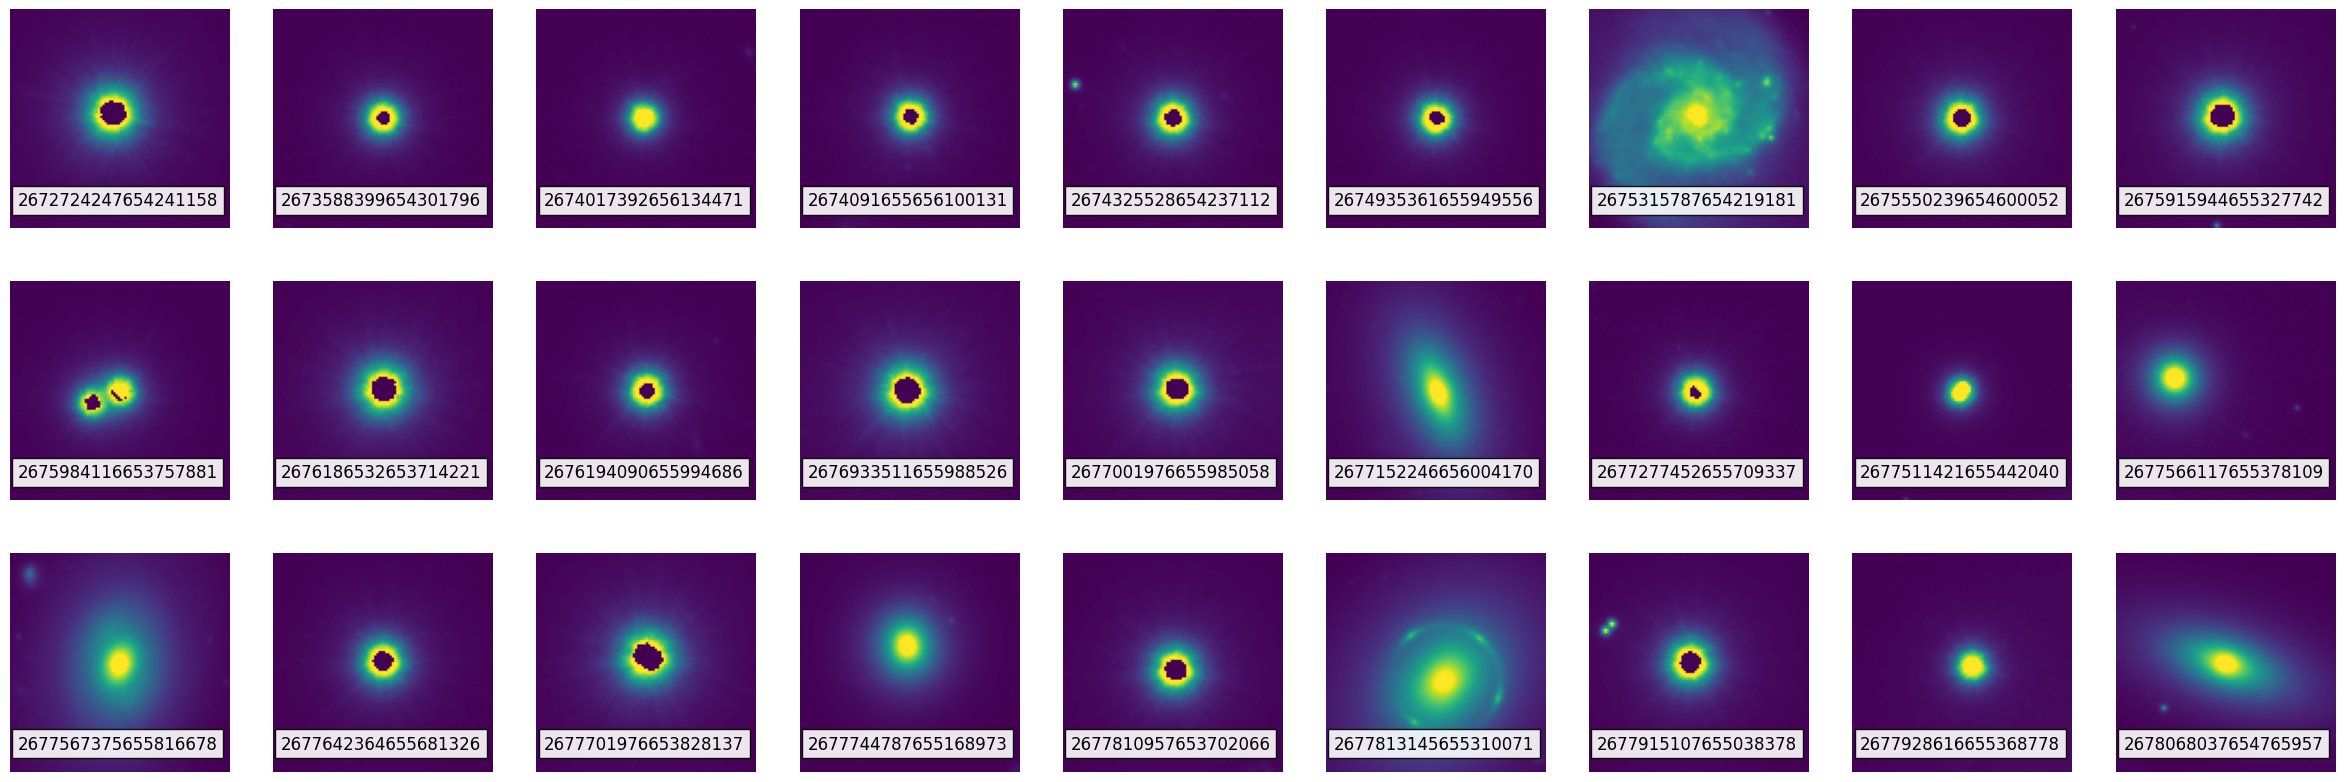

In [19]:
# Cutouts generation ============
subset      = res
cutout_r    = 10 * u.arcsecond # Cutout size (height x weight)
cutout_list = []

list_title  = [f"{inp}"                                       for inp in range(len(subset))]
list_date   = [f"{inp['reference_observation_date_time']}"    for inp in subset]
coords      = [SkyCoord(inp['right_ascension']*u.deg, inp['declination']* u.deg)   for inp in subset]


for ii in range(len(subset)):
    file_path  = f"{subset['datalabs_path'][ii]}/{subset['file_name'][ii]}"
    
    hdul          = fits.open(file_path)
    data          = hdul[0].data
    header        = hdul[0].header
    cutout        = Cutout2D(mode = 'partial', fill_value = 0.0, data=data, position = coords[ii], size= cutout_r, wcs=wcs.WCS(header))    
    cutout_list.append(cutout)
    hdul.close()

# Plot images ===================
plt.figure(figsize=[30,10])

for ii in range(len(subset)):
    ax = plt.subplot(3,9,1 + ii)    
    ax.imshow(cutout_list[ii].data, cmap='viridis', origin='lower', norm = ImageNormalize(cutout_list[ii].data, interval=PercentileInterval(99.), stretch=AsinhStretch()))
    
    x, y, w, h = 3, 5, 0, 0
    ax.text(x, y + h + 5, subset['object_id'][ii],fontsize=12,bbox=dict(facecolor='white', alpha=0.9))
    ax.axis('off')

plt.show()